# Phase II — What Did the Model Learn?

## Judging a Book by Its Cover
### Genre Bias & Visual Stereotypes in AI

**Team:** Marshmallow Bunnies

**Track:** Human-only Pair

**Model:** CLIP ViT-B/32

**Dataset:** BookCover30

## 2. Environment and Data Preparation

### 2.1 Project Setup

We use the same dataset and classification results as in Phase I
to ensure consistency and comparability between the two phases.

Project paths are defined dynamically to ensure reproducibility
across different operating systems and local environments.

In [1]:
from pathlib import Path
import pandas as pd

PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "archive"
IMAGE_DIR = DATA_DIR / "title30cat" / "224x224"
RESULTS_PATH = PROJECT_DIR / "data" / "clip_predictions.csv"

print("Project directory:", PROJECT_DIR)
print("Dataset exists:", DATA_DIR.is_dir())
print("Image directory exists:", IMAGE_DIR.is_dir())
print("Phase I results exist:", RESULTS_PATH.is_file())

Project directory: C:\Users\User\Desktop\JKU\Visualization
Dataset exists: True
Image directory exists: True
Phase I results exist: True


### 2.2 Loading Phase I Results

We reuse the original sample of 3,000 book covers from Phase I,
containing 500 images for each of the six selected genres.

The saved classification results provide the foundation for
investigating the relationship between model behavior and
internal representations in Phase II.

Image paths are reconstructed dynamically to ensure compatibility
across different local environments.

In [3]:
df = pd.read_csv(RESULTS_PATH)

print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

df.head()

Dataset shape: (3000, 20)

Available columns:
['Amazon Index (ASIN)', 'Filename', 'Image URL', 'Title', 'Author', 'Category ID', 'Category', 'image_path', 'image_exists', 'predicted_genre', 'confidence', 'prob_0', 'prob_1', 'prob_2', 'prob_3', 'prob_4', 'prob_5', 'correct', 'descriptive_prediction', 'descriptive_correct']


,Amazon Index (ASIN),Filename,Image URL,Title,Author,Category ID,Category,image_path,image_exists,predicted_genre,confidence,prob_0,prob_1,prob_2,prob_3,prob_4,prob_5,correct,descriptive_prediction,descriptive_correct
0,761526463,0761526463.jpg,http://ecx.images-amazon.com/images/I/51FRDny0...,The Real Lincoln: A New Look at Abraham Lincol...,Thomas DiLorenzo,1,Biographies & Memoirs,archive/title30cat/224x224/0761526463.jpg,True,History,0.544140,0.002037,0.003603,0.001633,0.544140,0.445583,0.003004,False,History,False
1,804139377,0804139377.jpg,http://ecx.images-amazon.com/images/I/51PMjKRg...,Brady vs Manning: The Untold Story of the Riva...,Gary Myers,1,Biographies & Memoirs,archive/title30cat/224x224/0804139377.jpg,True,Biographies & Memoirs,0.589095,0.017394,0.025131,0.002921,0.342709,0.589095,0.022751,True,History,False
2,1600787711,1600787711.jpg,http://ecx.images-amazon.com/images/I/51I-Jg4h...,Hockeytown Doc: A Half-Century of Red Wings St...,Dr. John Finley,1,Biographies & Memoirs,archive/title30cat/224x224/1600787711.jpg,True,Biographies & Memoirs,0.582719,0.009381,0.013589,0.006991,0.368249,0.582719,0.019070,True,History,False
3,670888125,0670888125.jpg,http://ecx.images-amazon.com/images/I/51D2GXVX...,Wooden Boats,Michael Ruhlman,1,Biographies & Memoirs,archive/title30cat/224x224/0670888125.jpg,True,Biographies & Memoirs,0.442351,0.163939,0.176535,0.004146,0.136468,0.442351,0.076562,True,History,False
4,71781773,0071781773.jpg,http://ecx.images-amazon.com/images/I/51xluzzt...,"Tell It Slant, 2nd Edition",Brenda Miller,1,Biographies & Memoirs,archive/title30cat/224x224/0071781773.jpg,True,Biographies & Memoirs,0.339129,0.169402,0.047246,0.069800,0.036468,0.339129,0.337955,True,History,False


In [4]:
df["image_path"] = df["Filename"].apply(
    lambda filename: IMAGE_DIR / filename
)

df["image_exists"] = df["image_path"].apply(
    lambda path: path.is_file()
)

print("Total covers:", len(df))
print("Available images:", df["image_exists"].sum())
print("Missing images:", (~df["image_exists"]).sum())

Total covers: 3000
Available images: 3000
Missing images: 0


In [5]:
print("Genre distribution:")
print(df["Category"].value_counts())

print("\nPhase I classification accuracy:")
print(f"{df['correct'].mean():.2%}")

Genre distribution:
Biographies & Memoirs           500
Children's Books                500
History                         500
Mystery, Thriller & Suspense    500
Romance                         500
Science Fiction & Fantasy       500
Name: Category, dtype: int64

Phase I classification accuracy:
62.33%


### 2.3 Model Initialization

We use the same pretrained CLIP ViT-B/32 model as in Phase I
to ensure consistency between the two phases.

Unlike Phase I, where CLIP was treated as a black-box
classifier, Phase II investigates its internal representations
and learned visual and semantic features.

The model is used without additional training or fine-tuning.

In [6]:
import torch
from transformers import CLIPModel, CLIPProcessor

MODEL_NAME = "openai/clip-vit-base-patch32"

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

model = CLIPModel.from_pretrained(MODEL_NAME).to(device)
processor = CLIPProcessor.from_pretrained(MODEL_NAME)

model.eval()

print("Model:", MODEL_NAME)
print("Device:", device)
print("Training mode:", model.training)

Model: openai/clip-vit-base-patch32
Device: cpu
Training mode: False


## 3. Exploring CLIP Architecture

### 3.1 Model Configuration

Before investigating the internal representations of CLIP,
we examine its architecture and configuration.

Understanding the structure of the vision and text encoders
helps us identify the internal representations available
for further analysis.

We inspect the number of transformer layers, attention heads,
hidden dimensions, image patch size, and the dimensionality
of the shared embedding space.

In [8]:
vision_config = model.config.vision_config
text_config = model.config.text_config

print("Vision Encoder:")
print(vision_config)

print("\nText Encoder:")
print(text_config)

architecture_df = pd.DataFrame({
    "Parameter": [
        "Transformer layers",
        "Hidden size",
        "Attention heads",
        "MLP intermediate size",
        "Projection dimension"
    ],
    "Vision Encoder": [
        vision_config.num_hidden_layers,
        vision_config.hidden_size,
        vision_config.num_attention_heads,
        vision_config.intermediate_size,
        model.config.projection_dim
    ],
    "Text Encoder": [
        text_config.num_hidden_layers,
        text_config.hidden_size,
        text_config.num_attention_heads,
        text_config.intermediate_size,
        model.config.projection_dim
    ]
})

architecture_df

Vision Encoder:
CLIPVisionConfig {
  "attention_dropout": 0.0,
  "dropout": 0.0,
  "hidden_act": "quick_gelu",
  "hidden_size": 768,
  "image_size": 224,
  "initializer_factor": 1.0,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-05,
  "model_type": "clip_vision_model",
  "num_attention_heads": 12,
  "num_channels": 3,
  "num_hidden_layers": 12,
  "patch_size": 32,
  "projection_dim": 512,
  "transformers_version": "4.41.0"
}


Text Encoder:
CLIPTextConfig {
  "attention_dropout": 0.0,
  "bos_token_id": 0,
  "dropout": 0.0,
  "eos_token_id": 2,
  "hidden_act": "quick_gelu",
  "hidden_size": 512,
  "initializer_factor": 1.0,
  "initializer_range": 0.02,
  "intermediate_size": 2048,
  "layer_norm_eps": 1e-05,
  "max_position_embeddings": 77,
  "model_type": "clip_text_model",
  "num_attention_heads": 8,
  "num_hidden_layers": 12,
  "pad_token_id": 1,
  "projection_dim": 512,
  "transformers_version": "4.41.0",
  "vocab_size": 49408
}



,Parameter,Vision Encoder,Text Encoder
0,Transformer layers,12,12
1,Hidden size,768,512
2,Attention heads,12,8
3,MLP intermediate size,3072,2048
4,Projection dimension,512,512


### 3.2 Image Patch Structure

The Vision Transformer divides each input image into
non-overlapping patches.

Each patch is projected into a learned representation.
An additional CLS token is used to aggregate information
from the entire image.

The patch structure determines the spatial resolution
of patch-level representations and attention-based
visualizations.

In [9]:
image_size = vision_config.image_size
patch_size = vision_config.patch_size

patches_per_side = image_size // patch_size
num_patches = patches_per_side ** 2
num_tokens = num_patches + 1

print("Image size:", image_size)
print("Patch size:", patch_size)
print("Patches per side:", patches_per_side)
print("Number of image patches:", num_patches)
print("Total tokens including CLS:", num_tokens)

Image size: 224
Patch size: 32
Patches per side: 7
Number of image patches: 49
Total tokens including CLS: 50


### 3.3 Extracting Internal Representations from a Single Image

To understand how CLIP processes book covers internally,
we first examine a single image from our dataset.

We extract the hidden states of the vision encoder
and inspect how image representations are structured
across transformer layers.

This provides a foundation for subsequent analysis
of learned representations across different genres
and prediction outcomes.

Title: The Real Lincoln: A New Look at Abraham Lincoln, His Agenda, and an Unnecessary War
True genre: Biographies & Memoirs
Predicted genre: History
Confidence: 0.54413974
Original image size: (224, 224)


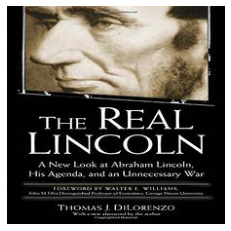

In [10]:
from PIL import Image
import matplotlib.pyplot as plt

sample = df.iloc[0]

image = Image.open(sample["image_path"]).convert("RGB")

print("Title:", sample["Title"])
print("True genre:", sample["Category"])
print("Predicted genre:", sample["predicted_genre"])
print("Confidence:", sample["confidence"])
print("Original image size:", image.size)

plt.figure(figsize=(4, 4))
plt.imshow(image)
plt.axis("off")
plt.show()

In [11]:
inputs = processor(
    images=image,
    return_tensors="pt"
).to(device)

pixel_values = inputs["pixel_values"]

print("Input tensor shape:", pixel_values.shape)
print("Data type:", pixel_values.dtype)
print("Device:", pixel_values.device)

Input tensor shape: torch.Size([1, 3, 224, 224])
Data type: torch.float32
Device: cpu


In [12]:
with torch.no_grad():
    vision_outputs = model.vision_model(
        pixel_values=pixel_values,
        output_hidden_states=True,
        return_dict=True
    )

hidden_states = vision_outputs.hidden_states

print("Number of hidden states:", len(hidden_states))

for layer_idx, layer_output in enumerate(hidden_states):
    print(f"Layer {layer_idx}: {layer_output.shape}")

Number of hidden states: 13
Layer 0: torch.Size([1, 50, 768])
Layer 1: torch.Size([1, 50, 768])
Layer 2: torch.Size([1, 50, 768])
Layer 3: torch.Size([1, 50, 768])
Layer 4: torch.Size([1, 50, 768])
Layer 5: torch.Size([1, 50, 768])
Layer 6: torch.Size([1, 50, 768])
Layer 7: torch.Size([1, 50, 768])
Layer 8: torch.Size([1, 50, 768])
Layer 9: torch.Size([1, 50, 768])
Layer 10: torch.Size([1, 50, 768])
Layer 11: torch.Size([1, 50, 768])
Layer 12: torch.Size([1, 50, 768])


### 3.4 Extracting the CLS Token and Final Image Embedding

We distinguish between intermediate CLS token representations
and the final projected image embedding.

While the CLS token representation has a dimensionality
of 768, the final image embedding is projected into
CLIP's 512-dimensional shared image-text embedding space.

In [13]:
final_hidden_state = hidden_states[-1]

cls_token = final_hidden_state[:, 0, :]

patch_tokens = final_hidden_state[:, 1:, :]

pooled_output = vision_outputs.pooler_output

with torch.no_grad():
    image_embedding = model.visual_projection(pooled_output)

print("Final hidden state:", final_hidden_state.shape)
print("CLS token:", cls_token.shape)
print("Patch tokens:", patch_tokens.shape)
print("Pooled output:", pooled_output.shape)
print("Final image embedding:", image_embedding.shape)

Final hidden state: torch.Size([1, 50, 768])
CLS token: torch.Size([1, 768])
Patch tokens: torch.Size([1, 49, 768])
Pooled output: torch.Size([1, 768])
Final image embedding: torch.Size([1, 512])


### 3.5 Visualizing Intermediate Representations

To gain an initial understanding of the internal representations
of CLIP, we inspect the CLS token representations across
different transformer layers.

Although the dimensionality remains constant throughout the
vision encoder, the numerical representations change as
the image is processed by successive transformer layers.

This preliminary exploration illustrates the structure of
hidden states before conducting systematic dataset-level analysis.

In [14]:
import numpy as np

cls_representations = torch.stack([
    layer[:, 0, :]
    for layer in hidden_states
])

cls_representations = (
    cls_representations.squeeze(1).cpu().numpy()
)

print("CLS representations shape:",
      cls_representations.shape)

CLS representations shape: (13, 768)


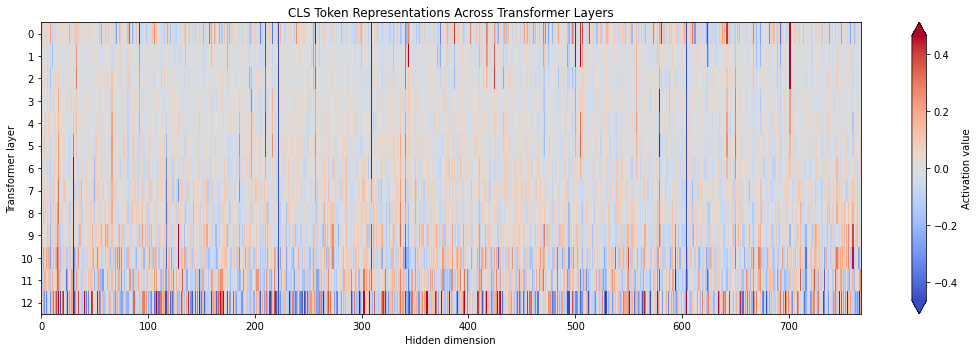

In [17]:
limit = np.percentile(np.abs(cls_representations), 99)

plt.figure(figsize=(15, 5))

plt.imshow(
    cls_representations,
    aspect="auto",
    cmap="coolwarm",
    vmin=-limit,
    vmax=limit,
    interpolation="nearest"
)

plt.colorbar(
    label="Activation value",
    extend="both"
)

plt.xlabel("Hidden dimension")
plt.ylabel("Transformer layer")
plt.yticks(range(len(hidden_states)))

plt.title("CLS Token Representations Across Transformer Layers")

plt.tight_layout()
plt.show()

The heatmap illustrates how the CLS token representation
changes across the transformer layers.

For the selected image, stronger activation variations
are visible in the later layers, particularly in the
final transformer layer.

Some hidden dimensions exhibit persistent activation
patterns across multiple layers.

However, activation magnitude alone does not indicate
semantic importance or contribution to the final prediction.

Since this visualization represents only a single image,
these observations cannot be generalized to the entire dataset.

## 4. Research Questions and Experimental Design

Building upon the findings from Phase I, this phase investigates the relationship between CLIP's internal image representations and its observed genre classification behavior.

Rather than focusing exclusively on the final model outputs, we examine how visual representations are organized and how they evolve across the transformer layers of the vision encoder.

### 4.1 Research Questions

- **RQ1:** How are different book genres organized in CLIP's learned image representation space?
- **RQ2:** How does genre separability evolve across the layers of the vision encoder?
- **RQ3:** How are systematic classification errors related to the structure of learned representations?

### 4.2 Experimental Design

We reuse the balanced dataset of 3,000 book covers and the classification results obtained in Phase I.

Our investigation focuses on intermediate CLS token representations and final projected image embeddings.

We consider both qualitative visualization and quantitative representation analysis to investigate the internal organization of book cover representations.

### 4.3 Visualization Techniques

Two complementary techniques are proposed:

1. **Dimensionality Reduction:** Visualizing high-dimensional representations in a two-dimensional space to investigate genre separation, overlapping regions, and classification error patterns.

2. **Layer-wise Representation Analysis:** Quantitatively examining how the organization and separability of genre representations change across transformer layers.

The results of both techniques will be compared to investigate whether visually observed patterns are supported by quantitative evidence in the original representation space.

The objective is not to improve classification accuracy but to better understand the learned representations associated with the model's observed behavior.

## 5. Technique I — Representation Space Visualization

### 5.1 Batch Extraction of Image Representations

To investigate the organization of learned representations,
we extract intermediate CLS token representations and final
projected image embeddings for all 3,000 book covers.

Instead of processing images individually, we use batch
processing to improve computational efficiency.

The extracted representations will be reused for dimensionality
reduction and layer-wise analysis without repeatedly running
the vision encoder.

In [18]:
from tqdm.auto import tqdm
import time

BATCH_SIZE = 16

REPRESENTATIONS_PATH = (
    PROJECT_DIR / "data" / "phase2_representations.npz"
)

print("Number of images:", len(df))
print("Batch size:", BATCH_SIZE)
print("Number of batches:", (len(df) + BATCH_SIZE - 1) // BATCH_SIZE)
print("Representations cache:", REPRESENTATIONS_PATH)

Number of images: 3000
Batch size: 16
Number of batches: 188
Representations cache: C:\Users\User\Desktop\JKU\Visualization\data\phase2_representations.npz


In [19]:
batch_df = df.iloc[:BATCH_SIZE]

batch_images = [
    Image.open(path).convert("RGB")
    for path in batch_df["image_path"]
]

batch_inputs = processor(
    images=batch_images,
    return_tensors="pt"
).to(device)

print("Number of images:", len(batch_images))
print("Input tensor shape:", batch_inputs["pixel_values"].shape)

Number of images: 16
Input tensor shape: torch.Size([16, 3, 224, 224])


### 5.1.3 Extracting Batch Representations

Before processing the complete dataset, we test the extraction
of intermediate CLS token representations and final image
embeddings on a single batch.

This allows us to verify tensor dimensions and estimate
the computational cost of processing the entire dataset.

In [20]:
start_time = time.perf_counter()

with torch.no_grad():
    batch_outputs = model.vision_model(
        pixel_values=batch_inputs["pixel_values"],
        output_hidden_states=True,
        return_dict=True
    )

    batch_cls = torch.stack(
        [layer[:, 0, :] for layer in batch_outputs.hidden_states],
        dim=1
    )

    batch_embeddings = model.visual_projection(
        batch_outputs.pooler_output
    )

elapsed_time = time.perf_counter() - start_time

print("CLS representations:", batch_cls.shape)
print("Final image embeddings:", batch_embeddings.shape)
print(f"Batch processing time: {elapsed_time:.2f} seconds")

CLS representations: torch.Size([16, 13, 768])
Final image embeddings: torch.Size([16, 512])
Batch processing time: 1.23 seconds


In [21]:
import torch.nn.functional as F

batch_embeddings_normalized = F.normalize(
    batch_embeddings,
    p=2,
    dim=-1
)

print("Normalized embeddings:",
      batch_embeddings_normalized.shape)

print("\nEmbedding norms before normalization:")
print(batch_embeddings.norm(dim=-1))

print("\nEmbedding norms after normalization:")
print(batch_embeddings_normalized.norm(dim=-1))

Normalized embeddings: torch.Size([16, 512])

Embedding norms before normalization:
tensor([ 9.8349,  9.7902,  8.8541,  9.0866,  8.9965,  8.8761,  9.5941,  9.1023,
         8.4653,  9.4888,  8.8450, 10.3834,  8.8550,  8.8886,  9.3740,  8.6559])

Embedding norms after normalization:
tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000])


### 5.2 Full Dataset Representation Extraction

After verifying the extraction pipeline on a single batch,
we process all 3,000 book covers.

For each image, we extract:

- CLS token representations from all 13 representation stages.
- Final projected image embeddings.
- L2-normalized final image embeddings.

The order of the extracted representations is preserved
to maintain alignment with the Phase I classification results.

The representations are cached to avoid repeated inference
during subsequent visualization and analysis.

In [22]:
def extract_representations(images):
    inputs = processor(
        images=images,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = model.vision_model(
            pixel_values=inputs["pixel_values"],
            output_hidden_states=True,
            return_dict=True
        )

        cls = torch.stack(
            [layer[:, 0, :] for layer in outputs.hidden_states],
            dim=1
        )

        embeddings = model.visual_projection(
            outputs.pooler_output
        )

        normalized_embeddings = F.normalize(
            embeddings,
            p=2,
            dim=-1
        )

    return (
        cls.cpu().numpy(),
        embeddings.cpu().numpy(),
        normalized_embeddings.cpu().numpy()
    )

In [23]:
test_cls, test_embeddings, test_normalized = (
    extract_representations(batch_images)
)

print("CLS representations:", test_cls.shape)
print("Raw embeddings:", test_embeddings.shape)
print("Normalized embeddings:", test_normalized.shape)

CLS representations: (16, 13, 768)
Raw embeddings: (16, 512)
Normalized embeddings: (16, 512)


In [24]:
all_cls = []
all_embeddings = []
all_normalized = []

start_time = time.perf_counter()

for start in tqdm(
    range(0, len(df), BATCH_SIZE),
    desc="Extracting representations"
):
    batch_df = df.iloc[start:start + BATCH_SIZE]

    images = []

    for path in batch_df["image_path"]:
        with Image.open(path) as img:
            images.append(img.convert("RGB"))

    cls, embeddings, normalized = (
        extract_representations(images)
    )

    all_cls.append(cls)
    all_embeddings.append(embeddings)
    all_normalized.append(normalized)

all_cls = np.concatenate(all_cls, axis=0)
all_embeddings = np.concatenate(all_embeddings, axis=0)
all_normalized = np.concatenate(all_normalized, axis=0)

elapsed_time = time.perf_counter() - start_time

print("\nCLS representations:", all_cls.shape)
print("Raw embeddings:", all_embeddings.shape)
print("Normalized embeddings:", all_normalized.shape)

print(f"\nTotal processing time: {elapsed_time / 60:.2f} minutes")

Extracting representations:   0%|          | 0/188 [00:00<?, ?it/s]


CLS representations: (3000, 13, 768)
Raw embeddings: (3000, 512)
Normalized embeddings: (3000, 512)

Total processing time: 2.58 minutes


### 5.3 Saving Extracted Representations

The extracted representations are saved locally together
with the corresponding image filenames.

This enables reproducible analysis and ensures that the
representations can be correctly aligned with the
classification results from Phase I.

In [25]:
np.savez_compressed(
    REPRESENTATIONS_PATH,
    cls_representations=all_cls,
    image_embeddings=all_embeddings,
    normalized_embeddings=all_normalized,
    filenames=df["Filename"].astype(str).to_numpy(dtype=str),
    model_name=np.array(MODEL_NAME)
)

print("Representations saved to:")
print(REPRESENTATIONS_PATH)

print(
    f"File size: "
    f"{REPRESENTATIONS_PATH.stat().st_size / 1024**2:.2f} MB"
)

Representations saved to:
C:\Users\User\Desktop\JKU\Visualization\data\phase2_representations.npz
File size: 117.29 MB


### 5.4 Loading and Validating Cached Representations

To avoid repeated model inference, we load the previously
extracted representations from the cache.

We verify the dimensionality of the stored arrays, the model
identifier, the alignment of image filenames, and the
normalization of the final image embeddings.

In [26]:
with np.load(REPRESENTATIONS_PATH, allow_pickle=False) as cached:
    all_cls = cached["cls_representations"]
    all_embeddings = cached["image_embeddings"]
    all_normalized = cached["normalized_embeddings"]
    cached_filenames = cached["filenames"]
    cached_model = cached["model_name"].item()

print("CLS representations:", all_cls.shape)
print("Raw embeddings:", all_embeddings.shape)
print("Normalized embeddings:", all_normalized.shape)

print("\nCached model:", cached_model)
print("Model matches:", cached_model == MODEL_NAME)

filenames_match = np.array_equal(
    cached_filenames,
    df["Filename"].astype(str).to_numpy(dtype=str)
)

print("Filenames match:", filenames_match)

norms = np.linalg.norm(all_normalized, axis=1)

print("All embeddings normalized:",
      np.allclose(norms, 1.0, atol=1e-5))

print("All values finite:",
      all(np.isfinite(arr).all()
          for arr in [all_cls, all_embeddings, all_normalized]))

CLS representations: (3000, 13, 768)
Raw embeddings: (3000, 512)
Normalized embeddings: (3000, 512)

Cached model: openai/clip-vit-base-patch32
Model matches: True
Filenames match: True
All embeddings normalized: True
All values finite: True


### 5.5 PCA of Final Image Embeddings

We apply Principal Component Analysis (PCA) to the
512-dimensional normalized image embeddings.

The embeddings are projected into a two-dimensional space
to explore their organization and the potential separation
of different book genres.

Genre labels are used only for visualization and are not
involved in fitting the PCA transformation.

We also inspect the explained variance ratio to understand
how much information is preserved by the projection.

In [27]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)

embeddings_2d = pca.fit_transform(all_normalized)

print("Original shape:", all_normalized.shape)
print("Reduced shape:", embeddings_2d.shape)

print("\nExplained variance ratio:")
print(f"PC1: {pca.explained_variance_ratio_[0]:.2%}")
print(f"PC2: {pca.explained_variance_ratio_[1]:.2%}")

print(
    f"Total explained variance: "
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

Original shape: (3000, 512)
Reduced shape: (3000, 2)

Explained variance ratio:
PC1: 4.46%
PC2: 4.02%
Total explained variance: 8.48%


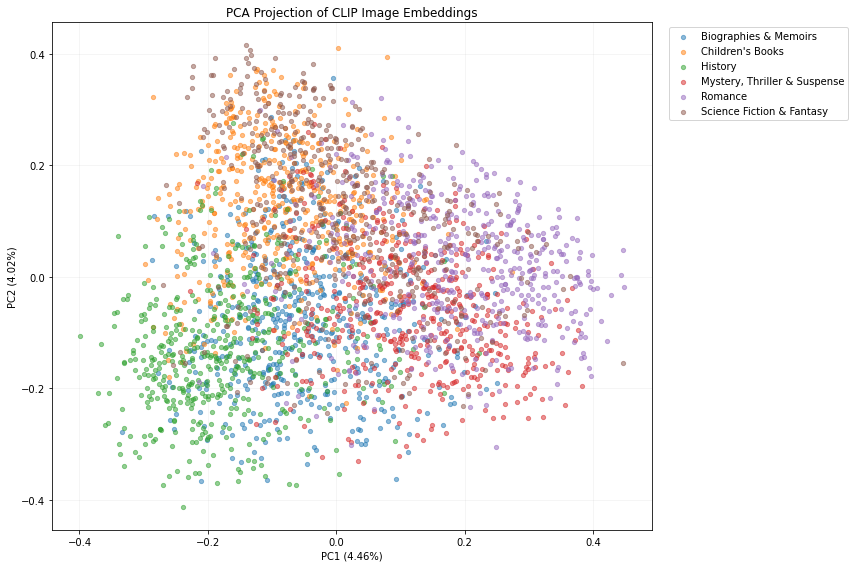

In [28]:
df["PC1"] = embeddings_2d[:, 0]
df["PC2"] = embeddings_2d[:, 1]

genres = sorted(df["Category"].unique())

colors = plt.get_cmap("tab10").colors

genre_colors = {
    genre: colors[i]
    for i, genre in enumerate(genres)
}

plt.figure(figsize=(12, 8))

for genre in genres:
    subset = df[df["Category"] == genre]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=genre,
        color=genre_colors[genre],
        alpha=0.5,
        s=18
    )

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]:.2%})"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]:.2%})"
)

plt.title("PCA Projection of CLIP Image Embeddings")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.15)
plt.tight_layout()
plt.show()

The PCA projection reveals a partially structured
representation space, with different book genres
concentrated in different regions.

However, substantial overlap remains between genres,
particularly in the central regions of the projection.

The first two principal components explain only 8.48%
of the total variance. Therefore, the observed spatial
relationships should be interpreted cautiously.

Further analysis in the original high-dimensional
representation space is necessary to verify whether
these patterns are associated with systematic
classification errors.

In [29]:
pca_full = PCA(svd_solver="full")
pca_full.fit(all_normalized)

cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
)

for threshold in [0.50, 0.80, 0.90, 0.95, 0.99]:
    n_components = np.searchsorted(
        cumulative_variance, threshold
    ) + 1

    print(
        f"{threshold:.0%} explained variance: "
        f"{n_components} components"
    )

50% explained variance: 50 components
80% explained variance: 150 components
90% explained variance: 231 components
95% explained variance: 304 components
99% explained variance: 421 components


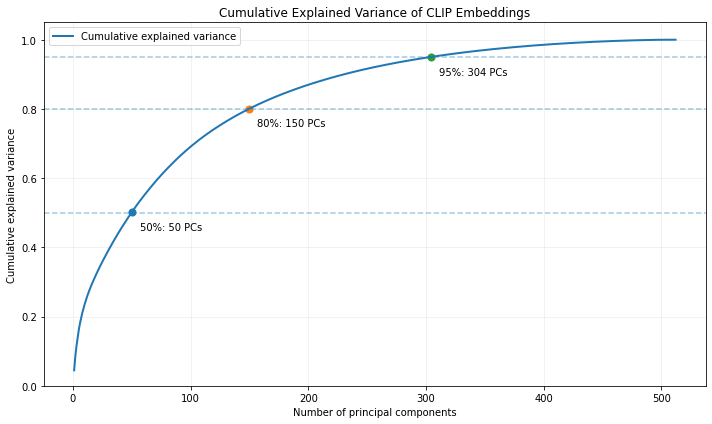

In [30]:
plt.figure(figsize=(10, 6))

plt.plot(
    np.arange(1, len(cumulative_variance) + 1),
    cumulative_variance,
    linewidth=2,
    label="Cumulative explained variance"
)

for threshold in [0.50, 0.80, 0.95]:
    n = np.searchsorted(
        cumulative_variance, threshold
    ) + 1

    plt.axhline(
        threshold,
        linestyle="--",
        alpha=0.4
    )

    plt.scatter(
        n,
        cumulative_variance[n - 1],
        s=50
    )

    plt.annotate(
        f"{threshold:.0%}: {n} PCs",
        (n, cumulative_variance[n - 1]),
        xytext=(8, -18),
        textcoords="offset points"
    )

plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative Explained Variance of CLIP Embeddings")
plt.ylim(0, 1.05)
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

The cumulative explained variance analysis shows that
50 principal components are required to explain 50%
of the total variance, 150 components to explain 80%,
and 304 components to explain 95%.

This indicates that the variance of CLIP's image
representations is distributed across a substantial
number of dimensions.

Since the two-dimensional PCA projection explains
only 8.48% of the total variance, its visual patterns
must be complemented by quantitative analysis in
the original high-dimensional representation space.

### 5.7 Correct and Incorrect Predictions in Representation Space

To investigate the relationship between learned
representations and classification errors, we visualize
correctly and incorrectly classified book covers in
the same PCA projection.

The objective is to explore whether classification
errors are concentrated in particular regions of
the representation space or distributed throughout it.

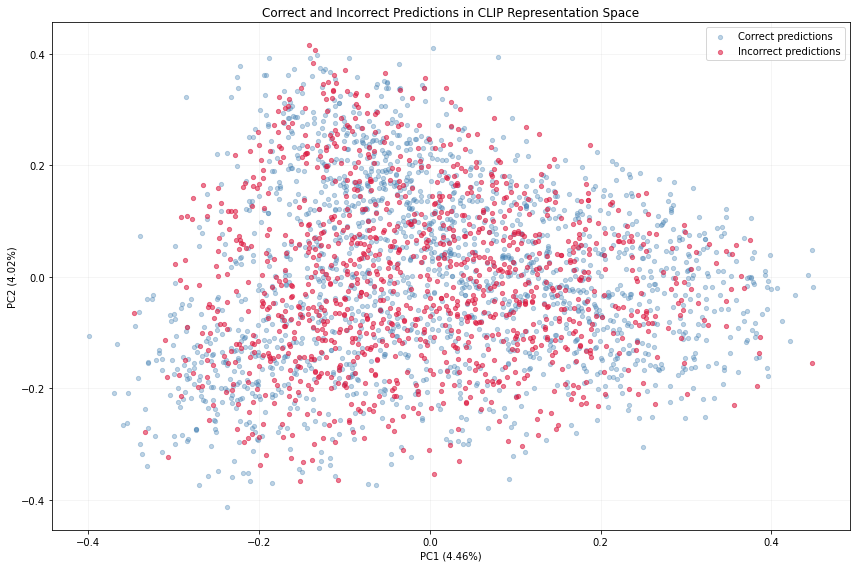

In [31]:
correct_mask = df["correct"] == True
incorrect_mask = df["correct"] == False

plt.figure(figsize=(12, 8))

plt.scatter(
    df.loc[correct_mask, "PC1"],
    df.loc[correct_mask, "PC2"],
    color="steelblue",
    alpha=0.35,
    s=18,
    label="Correct predictions"
)

plt.scatter(
    df.loc[incorrect_mask, "PC1"],
    df.loc[incorrect_mask, "PC2"],
    color="crimson",
    alpha=0.55,
    s=18,
    label="Incorrect predictions"
)

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]:.2%})"
)
plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]:.2%})"
)

plt.title("Correct and Incorrect Predictions in CLIP Representation Space")

plt.legend()
plt.grid(alpha=0.15)
plt.tight_layout()
plt.show()

Correctly and incorrectly classified book covers exhibit
substantial overlap in the two-dimensional PCA projection.

No clearly isolated regions of classification errors
are observed.

However, point density and overplotting make it difficult
to determine whether certain regions are associated with
higher error rates.

A local error rate visualization is therefore needed
to investigate this relationship more systematically.

Overall error rate: 37.67%


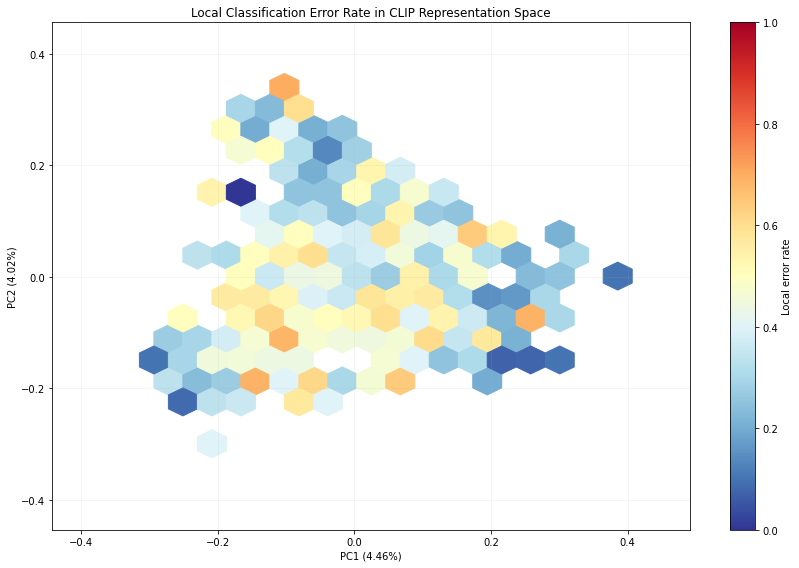

In [32]:
error_indicator = (~df["correct"].astype(bool)).astype(int)

overall_error_rate = error_indicator.mean()

print(f"Overall error rate: {overall_error_rate:.2%}")

plt.figure(figsize=(12, 8))

hb = plt.hexbin(
    df["PC1"],
    df["PC2"],
    C=error_indicator,
    reduce_C_function=np.mean,
    gridsize=20,
    mincnt=10,
    cmap="RdYlBu_r",
    vmin=0,
    vmax=1
)

plt.colorbar(hb, label="Local error rate")

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]:.2%})"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]:.2%})"
)

plt.title("Local Classification Error Rate in CLIP Representation Space")

plt.grid(alpha=0.15)
plt.tight_layout()
plt.show()

The local error rate visualization reveals a heterogeneous
distribution of classification errors across the PCA space.

Several central regions exhibit elevated error rates,
while some peripheral regions are associated with
lower error rates.

These observations suggest that classification difficulty
may be related to the organization and overlap of genre
representations.

However, the two-dimensional projection captures only
a small proportion of the total variance. Local error
rates may also be influenced by differences in genre
composition and sample density.

Further analysis of specific confusion patterns and
high-dimensional representations is required.

### 5.9 Investigating History–Biography Confusion

Phase I revealed systematic confusion between History
and Biographies & Memoirs.

In particular, 127 History book covers were incorrectly
classified as Biographies & Memoirs.

We investigate whether these classification errors
are associated with the spatial organization of
the learned image representations.

#### 5.9.1 Visualizing the Confusion Groups

We compare correctly classified History covers,
History covers misclassified as Biographies & Memoirs,
other History classification errors, and true
Biographies & Memoirs covers within the same
PCA projection.

In [33]:
history_genre = "History"
biography_genre = "Biographies & Memoirs"

history_df = df[
    df["Category"] == history_genre
]

biography_df = df[
    df["Category"] == biography_genre
]

history_correct = history_df[
    history_df["predicted_genre"] == history_genre
]

history_to_biography = history_df[
    history_df["predicted_genre"] == biography_genre
]

history_other_errors = history_df[
    ~history_df["predicted_genre"].isin(
        [history_genre, biography_genre]
    )
]

print("History — correct:", len(history_correct))
print("History → Biography:", len(history_to_biography))
print("History — other errors:", len(history_other_errors))
print("Biography covers:", len(biography_df))

History — correct: 297
History → Biography: 127
History — other errors: 76
Biography covers: 500


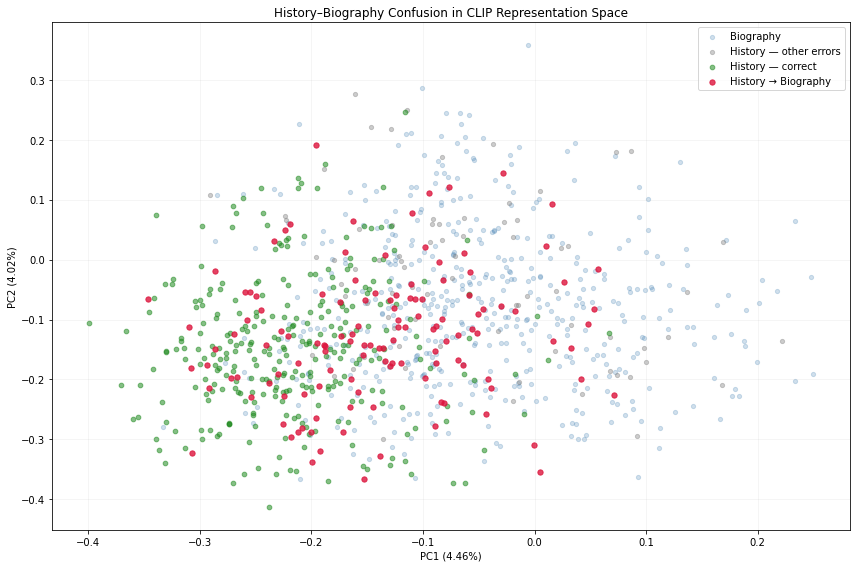

In [34]:
plt.figure(figsize=(12, 8))

groups = [
    (biography_df, "Biography", "steelblue", 0.25, 18),
    (history_other_errors, "History — other errors", "gray", 0.4, 18),
    (history_correct, "History — correct", "forestgreen", 0.55, 22),
    (history_to_biography, "History → Biography", "crimson", 0.8, 28)
]

for subset, label, color, alpha, size in groups:
    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=label,
        color=color,
        alpha=alpha,
        s=size
    )

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]:.2%})"
)
plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]:.2%})"
)

plt.title("History–Biography Confusion in CLIP Representation Space")

plt.legend()
plt.grid(alpha=0.15)
plt.tight_layout()
plt.show()

The PCA projection suggests a partial separation between
correctly classified History covers and true Biography covers.

History covers misclassified as Biography frequently appear
within the overlapping regions of the two genres, although
some remain within the region occupied by correctly
classified History covers.

This suggests a potential relationship between representation
similarity and systematic classification errors.

However, quantitative analysis in the original
512-dimensional embedding space is necessary to verify
this observation.

#### 5.9.2 Cosine Similarity to Genre Centroids

To verify the patterns observed in the PCA projection,
we analyze cosine similarities in the original
512-dimensional embedding space.

We compute genre centroids for History and
Biographies & Memoirs.

For each History cover, we calculate its cosine
similarity to both genre centroids and the difference
between these similarities.

A leave-one-out approach is used for the History
centroid to prevent each image from contributing
to its own reference representation.

In [36]:
history_mask = df["Category"].eq(history_genre).to_numpy()
biography_mask = df["Category"].eq(biography_genre).to_numpy()

history_embeddings = all_normalized[history_mask]
biography_embeddings = all_normalized[biography_mask]

print("History embeddings:", history_embeddings.shape)
print("Biography embeddings:", biography_embeddings.shape)

History embeddings: (500, 512)
Biography embeddings: (500, 512)


In [37]:
biography_centroid = biography_embeddings.mean(axis=0)

biography_centroid = (
    biography_centroid / np.linalg.norm(biography_centroid)
)

history_sum = history_embeddings.sum(axis=0)

history_centroids_loo = (
    history_sum - history_embeddings
) / (len(history_embeddings) - 1)

history_centroids_loo /= np.linalg.norm(
    history_centroids_loo,
    axis=1,
    keepdims=True
)

print("Biography centroid:", biography_centroid.shape)
print("History LOO centroids:", history_centroids_loo.shape)

Biography centroid: (512,)
History LOO centroids: (500, 512)


In [38]:
similarity_to_history = np.sum(
    history_embeddings * history_centroids_loo,
    axis=1
)

similarity_to_biography = (
    history_embeddings @ biography_centroid
)

history_analysis = df.loc[history_mask].copy()

history_analysis["similarity_to_history"] = (
    similarity_to_history
)

history_analysis["similarity_to_biography"] = (
    similarity_to_biography
)

history_analysis["similarity_margin"] = (
    similarity_to_biography - similarity_to_history
)

history_analysis[
    [
        "Title",
        "predicted_genre",
        "similarity_to_history",
        "similarity_to_biography",
        "similarity_margin"
    ]
].head()

,Title,predicted_genre,similarity_to_history,similarity_to_biography,similarity_margin
1000,"Genesis, Rogers Rangers: The First Green Beret...",Biographies & Memoirs,0.601928,0.624674,0.022746
1001,Yucatan Before and After the Conquest (Native ...,Science Fiction & Fantasy,0.612514,0.558238,-0.054276
1002,AKs and Lollipops: Inside The Syrian Conflict,History,0.511964,0.446503,-0.065461
1003,Olmec Archaeology and Early Mesoamerica (Cambr...,History,0.685274,0.597020,-0.088254
1004,Common Sense (Little Books of Wisdom),Science Fiction & Fantasy,0.645360,0.648984,0.003624


In [39]:
history_analysis["prediction_group"] = np.select(
    [
        history_analysis["predicted_genre"].eq(history_genre),
        history_analysis["predicted_genre"].eq(biography_genre)
    ],
    [
        "Correct History",
        "History → Biography"
    ],
    default="Other errors"
)

history_summary = history_analysis.groupby(
    "prediction_group"
).agg(
    count=("similarity_margin", "size"),
    mean_history_similarity=("similarity_to_history", "mean"),
    mean_biography_similarity=("similarity_to_biography", "mean"),
    mean_margin=("similarity_margin", "mean"),
    median_margin=("similarity_margin", "median"),
    std_margin=("similarity_margin", "std")
)

history_summary.round(4)

,count,mean_history_similarity,mean_biography_similarity,mean_margin,median_margin,std_margin
prediction_group,,,,,,
Correct History,297,0.6660,0.6173,-0.0487,-0.0492,0.0324
History → Biography,127,0.6295,0.6198,-0.0097,-0.0106,0.0334
Other errors,76,0.6212,0.6260,0.0048,0.0032,0.0277


#### 5.9.3 Distribution of Similarity Margins

Mean similarity values provide an overview of differences
between prediction groups but do not capture the full
distribution of individual observations.

We therefore visualize the distribution of similarity
margins to investigate group variability, overlap,
and potential outliers.

A negative margin indicates greater similarity to the
History centroid, whereas a positive margin indicates
greater similarity to the Biography centroid.

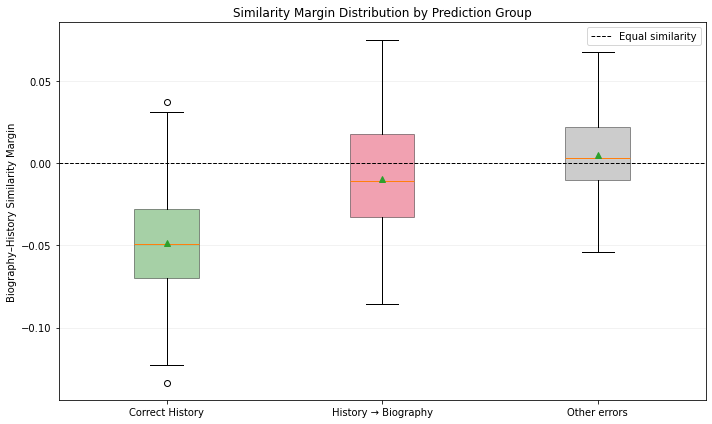

In [42]:
group_order = [
    "Correct History",
    "History → Biography",
    "Other errors"
]

margin_data = [
    history_analysis.loc[
        history_analysis["prediction_group"] == group,
        "similarity_margin"
    ].to_numpy()
    for group in group_order
]

plt.figure(figsize=(10, 6))

boxplot = plt.boxplot(
    margin_data,
    tick_labels=group_order,
    patch_artist=True,
    showmeans=True
)

group_colors = [
    "forestgreen",
    "crimson",
    "gray"
]

for patch, color in zip(
    boxplot["boxes"], group_colors
):
    patch.set_facecolor(color)
    patch.set_alpha(0.4)

plt.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Equal similarity"
)

plt.ylabel("Biography–History Similarity Margin")

plt.title(
    "Similarity Margin Distribution by Prediction Group"
)

plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

In [43]:
positive_margin_summary = (
    history_analysis
    .groupby("prediction_group")["similarity_margin"]
    .agg(
        total="size",
        positive_count=lambda x: (x > 0).sum(),
        positive_rate=lambda x: (x > 0).mean()
    )
)

positive_margin_summary["positive_rate"] *= 100

positive_margin_summary.round(2)

,total,positive_count,positive_rate
prediction_group,,,
Correct History,297,22,7.41
History → Biography,127,49,38.58
Other errors,76,47,61.84


The similarity margin distributions reveal differences
between correctly and incorrectly classified History covers.

Only 7.41% of correctly classified History covers are closer
to the Biography centroid than to the History centroid.

This proportion increases to 38.58% for History covers
misclassified as Biography and to 61.84% for other
classification errors.

Interestingly, the History-to-Biography error group is
characterized primarily by reduced similarity to its true
genre centroid rather than substantially increased
similarity to the Biography centroid.

These findings suggest that reduced alignment with the
true genre representation may be associated with
classification errors more generally.

However, image-centroid similarities do not directly
determine CLIP's predictions, which are based on
image-text similarities.

#### 5.9.4 Statistical Comparison of Prediction Groups

We conduct an exploratory statistical comparison of
similarity margins across the three History prediction groups.

The Kruskal-Wallis test is used to assess whether the
distributions differ across groups.

Pairwise Mann-Whitney U tests are subsequently applied
to identify differences between individual groups.

A Bonferroni correction is used to account for multiple
pairwise comparisons.

In [44]:
from scipy.stats import kruskal, mannwhitneyu

h_statistic, p_value = kruskal(*margin_data)

print(f"Kruskal-Wallis statistic: {h_statistic:.4f}")
print(f"p-value: {p_value:.4e}")

Kruskal-Wallis statistic: 165.8513
p-value: 9.6794e-37


In [45]:
from itertools import combinations

pairwise_results = []

pairs = list(combinations(range(len(group_order)), 2))

for i, j in pairs:

    group_a = margin_data[i]
    group_b = margin_data[j]

    u_stat, p = mannwhitneyu(
        group_a,
        group_b,
        alternative="two-sided"
    )

    effect_size = (
        2 * u_stat / (len(group_a) * len(group_b)) - 1
    )

    pairwise_results.append({
        "Group A": group_order[i],
        "Group B": group_order[j],
        "U statistic": u_stat,
        "p-value": p,
        "Adjusted p-value": min(p * len(pairs), 1.0),
        "Rank-biserial correlation": effect_size
    })

pairwise_df = pd.DataFrame(pairwise_results)

pairwise_df["Significant"] = (
    pairwise_df["Adjusted p-value"] < 0.05
)

pairwise_df

,Group A,Group B,U statistic,p-value,Adjusted p-value,Rank-biserial correlation,Significant
0,Correct History,History → Biography,7733.0,6.197590e-22,1.859277e-21,-0.589968,True
1,Correct History,Other errors,2401.0,3.224889e-26,9.674668e-26,-0.787259,True
2,History → Biography,Other errors,3629.0,3.138977e-03,9.416932e-03,-0.248031,True


The pairwise Mann–Whitney U tests reveal differences
between all three prediction groups after Bonferroni
correction.

The largest effect is observed between correctly
classified History covers and other classification errors
(rank-biserial correlation = -0.787).

A substantial difference is also observed between correctly
classified History covers and those misclassified as
Biographies & Memoirs (r = -0.590).

The difference between the two error groups is smaller
(r = -0.248).

Together with the centroid similarity analysis, these
results suggest that reduced similarity to the true genre
representation is associated with classification errors
more generally, rather than exclusively with
History-to-Biography confusion.

These statistical results should be interpreted as
exploratory because the similarity scores are derived
from shared genre centroids.

### 5.10 Investigating Romance–Thriller Confusion

Phase I revealed an association between darker Romance
book covers and incorrect Thriller predictions.

To investigate whether the representation patterns observed
for History–Biography confusion also occur in other genres,
we apply the same representation analysis to Romance
and Mystery, Thriller & Suspense.

This comparison helps us explore whether reduced alignment
with the true genre centroid is a more general characteristic
of classification errors.

#### 5.10.1 Creating Comparison Groups

In [46]:
romance_genre = "Romance"
thriller_genre = "Mystery, Thriller & Suspense"

romance_df = df[
    df["Category"] == romance_genre
]

thriller_df = df[
    df["Category"] == thriller_genre
]

romance_correct = romance_df[
    romance_df["predicted_genre"] == romance_genre
]

romance_to_thriller = romance_df[
    romance_df["predicted_genre"] == thriller_genre
]

romance_other_errors = romance_df[
    ~romance_df["predicted_genre"].isin(
        [romance_genre, thriller_genre]
    )
]

print("Romance — correct:", len(romance_correct))
print("Romance → Thriller:", len(romance_to_thriller))
print("Romance — other errors:", len(romance_other_errors))
print("Thriller covers:", len(thriller_df))

Romance — correct: 366
Romance → Thriller: 68
Romance — other errors: 66
Thriller covers: 500


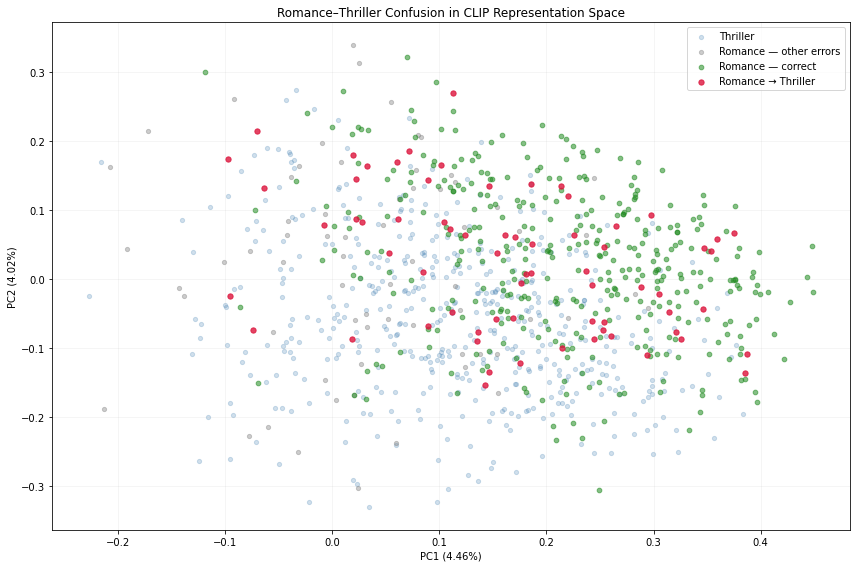

In [47]:
plt.figure(figsize=(12, 8))

groups = [
    (thriller_df, "Thriller", "steelblue", 0.25, 18),
    (romance_other_errors, "Romance — other errors", "gray", 0.4, 18),
    (romance_correct, "Romance — correct", "forestgreen", 0.55, 22),
    (romance_to_thriller, "Romance → Thriller", "crimson", 0.8, 28)
]

for subset, label, color, alpha, size in groups:
    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=label,
        color=color,
        alpha=alpha,
        s=size
    )

plt.xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]:.2%})"
)

plt.ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]:.2%})"
)

plt.title("Romance–Thriller Confusion in CLIP Representation Space")

plt.legend()
plt.grid(alpha=0.15)
plt.tight_layout()
plt.show()